# Окупаемость высшего образования
Что определяет окупаемость диплома (ROI) , то, что студент **выбрал** (специальность, стажировка, GPA), или то, что ему **досталось** (престиж вуза, селективность)?

**Данные:** `college_major_roi.csv` - 30 000 выпускников. Цель: `net_roi_usd` (чистая окупаемость за 10 лет, $) и `positive_roi` (окупился ли диплом, 0/1).

**Методы:** EDA · проверка гипотез (t-тест) · регрессия · классификация.

*Данные учебные (синтетические) — методология переносится на реальные (Rosstat, OECD).*


## 1. Загрузка и первичный осмотр

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams.update({"figure.dpi":110, "axes.spines.top":False, "axes.spines.right":False})

df = pd.read_csv("/content/college_major_roi (2).csv")
print(df.shape)
df.head()

(30000, 18)


,grad_id,major,major_category,institution_tier,institution_selectivity_pctile,gpa,had_internship,completed_on_time,region,net_cost_usd,debt_usd,hs_baseline_10yr_usd,added_earnings_10yr_usd,earnings_10yr_usd,net_roi_usd,roi_pct,positive_roi,high_roi
0,G000000,biology,STEM,mid_tier,52,2.58,0,0,south,144400,0,411700,101000,512700,-43400,-30.0,0,0
1,G000001,marketing,business,mid_tier,61,2.58,0,1,northeast,57400,0,356900,330600,687500,273200,476.1,1,0
2,G000002,electrical_engineering,STEM,top_public,78,3.14,1,1,northeast,65100,39600,339600,655100,994700,590000,906.4,1,1
3,G000003,marketing,business,top_public,77,3.04,0,1,midwest,105800,81300,399600,197500,597100,91700,86.8,1,0
4,G000004,marketing,business,ivy_elite,100,3.81,0,0,south,219200,93500,335700,222900,558600,3800,1.7,1,0


In [4]:
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 18 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   grad_id                         30000 non-null  object 
 1   major                           30000 non-null  object 
 2   major_category                  30000 non-null  object 
 3   institution_tier                30000 non-null  object 
 4   institution_selectivity_pctile  30000 non-null  int64  
 5   gpa                             30000 non-null  float64
 6   had_internship                  30000 non-null  int64  
 7   completed_on_time               30000 non-null  int64  
 8   region                          30000 non-null  object 
 9   net_cost_usd                    30000 non-null  int64  
 10  debt_usd                        30000 non-null  int64  
 11  hs_baseline_10yr_usd            30000 non-null  int64  
 12  added_earnings_10yr_usd         

,institution_selectivity_pctile,gpa,had_internship,completed_on_time,net_cost_usd,debt_usd,hs_baseline_10yr_usd,added_earnings_10yr_usd,earnings_10yr_usd,net_roi_usd,roi_pct,positive_roi,high_roi
count,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,3.000000e+04,3.000000e+04,3.000000e+04,30000.000000,30000.000000,30000.00000
mean,55.086067,3.093337,0.436067,0.682367,88621.496667,38498.063333,359893.416667,3.554752e+05,7.153680e+05,2.668537e+05,346.153987,0.835167,0.25000
std,18.593708,0.439060,0.495904,0.465564,33576.903160,37801.748200,39923.943255,2.948109e+05,2.977847e+05,2.949958e+05,398.666879,0.371036,0.43302
min,16.000000,1.500000,0.000000,0.000000,28500.000000,0.000000,250000.000000,1.000000e+04,2.723000e+05,-3.052000e+05,-92.100000,0.000000,0.00000
25%,42.000000,2.790000,0.000000,0.000000,65500.000000,0.000000,333100.000000,1.179000e+05,4.835000e+05,3.280000e+04,39.700000,1.000000,0.00000
50%,55.000000,3.100000,0.000000,1.000000,81000.000000,38700.000000,359700.000000,2.836500e+05,6.458000e+05,1.981000e+05,230.900000,1.000000,0.00000
75%,68.000000,3.400000,1.000000,1.000000,103600.000000,62300.000000,387300.000000,5.093000e+05,8.717000e+05,4.235250e+05,537.400000,1.000000,0.25000
max,102.000000,4.000000,1.000000,1.000000,352900.000000,331700.000000,480000.000000,2.894900e+06,3.245500e+06,2.755100e+06,3618.900000,1.000000,1.00000


## 2. EDA: что двигает окупаемость
Считаем **медианный** ROI (медиана честнее среднего: устойчива к выбросам-миллионерам, показывает типичного выпускника).

In [5]:
# по категории специальности
df.groupby("major_category")["net_roi_usd"].median().sort_values(ascending=False)

,net_roi_usd
major_category,
STEM,393350.0
health,318500.0
business,291700.0
social_science,22800.0
education,8750.0
humanities,-11200.0
arts,-35500.0


In [6]:
# по типу вуза
df.groupby("institution_tier")["net_roi_usd"].median().sort_values(ascending=False)

,net_roi_usd
institution_tier,
ivy_elite,304350.0
top_public,256300.0
mid_tier,216850.0
regional,195400.0
for_profit,68750.0


In [7]:
# эффект стажировки
df.groupby("had_internship")["net_roi_usd"].median()

,net_roi_usd
had_internship,
0,147950.0
1,264450.0


In [8]:
# окупается ли старание: GPA по диапазонам
df["gpa_group"] = pd.cut(df["gpa"], bins=[1,2,3,4], labels=["1-2","2-3","3-4"])
df.groupby("gpa_group", observed=True)["net_roi_usd"].median()

,net_roi_usd
gpa_group,
1-2,210800.0
2-3,188100.0
3-4,203600.0


In [9]:
# ключевой разрез: специальность x вуз
df.pivot_table(index="major_category", columns="institution_tier",
               values="net_roi_usd", aggfunc="median").round(0)

institution_tier,for_profit,ivy_elite,mid_tier,regional,top_public
major_category,,,,,
STEM,189850.0,593900.0,411350.0,369800.0,503100.0
arts,-85200.0,-83000.0,-34500.0,-23150.0,-35100.0
business,128750.0,415550.0,307100.0,274250.0,350800.0
education,-57300.0,-16200.0,15500.0,15550.0,10700.0
health,124200.0,402150.0,348000.0,303200.0,388900.0
humanities,-70050.0,-50200.0,-7800.0,-1500.0,-8950.0
social_science,-46700.0,2700.0,28500.0,30550.0,34800.0


In [10]:
# доля окупившихся дипломов по специальностям
df.groupby("major_category")["positive_roi"].mean().sort_values(ascending=False).round(3)

,positive_roi
major_category,
health,0.992
STEM,0.987
business,0.984
social_science,0.669
education,0.581
humanities,0.376
arts,0.111


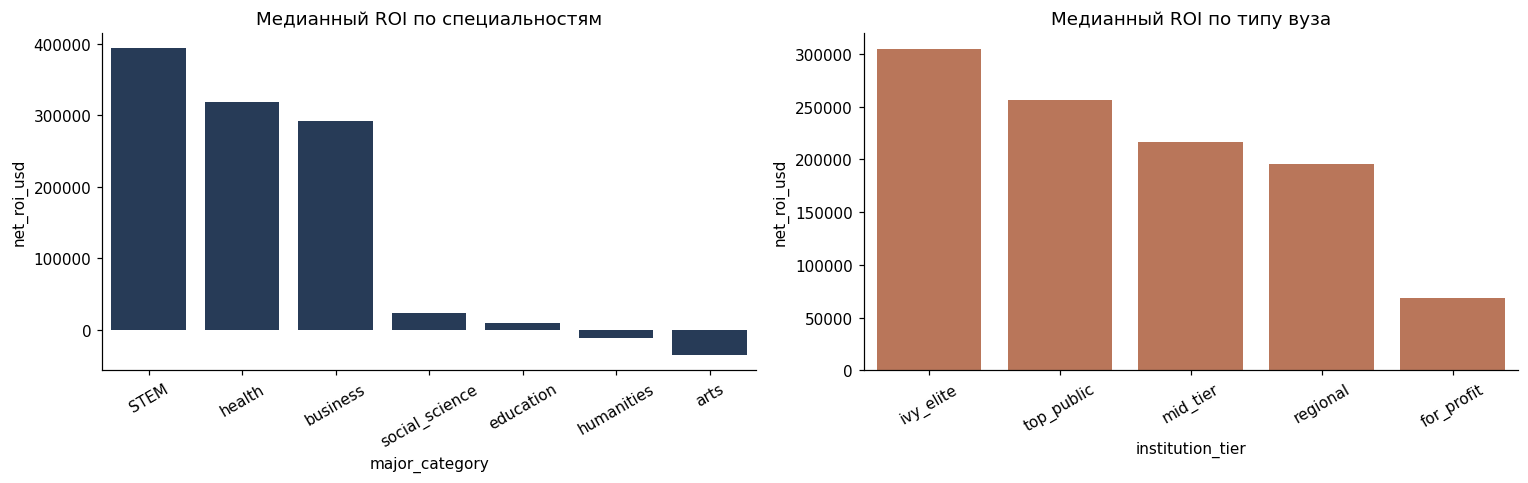

In [11]:
# графики
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
order1 = df.groupby("major_category")["net_roi_usd"].median().sort_values(ascending=False).index
sns.barplot(data=df, x="major_category", y="net_roi_usd", order=order1, estimator="median",
            errorbar=None, color="#1f3a5f", ax=ax[0])
ax[0].set_title("Медианный ROI по специальностям"); ax[0].tick_params(axis="x", rotation=30)
order2 = df.groupby("institution_tier")["net_roi_usd"].median().sort_values(ascending=False).index
sns.barplot(data=df, x="institution_tier", y="net_roi_usd", order=order2, estimator="median",
            errorbar=None, color="#c96f4a", ax=ax[1])
ax[1].set_title("Медианный ROI по типу вуза"); ax[1].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

**Наблюдение:** разброс ROI по специальностям (STEM vs гуманитарии) шире, чем по типам вузов. Первый намёк, что *выбор специальности* весит не меньше престижа вуза. Стажировка заметно поднимает медиану. Проверим это статистически и моделью.

## 3. Проверка гипотез (t-тест)
H₀: фактор не влияет на ROI. Если p-value < 0.05 то отвергаем H₀, влияние значимо.

In [12]:
from scipy import stats

def ttest_report(mask_col, val_a, val_b, name):
    a = df[df[mask_col]==val_a]["net_roi_usd"]
    b = df[df[mask_col]==val_b]["net_roi_usd"]
    t, p = stats.ttest_ind(a, b, equal_var=False)
    print(f"{name}: среднее A={a.mean():.0f}, B={b.mean():.0f} | p-value={p:.2e} -> "
          f"{'значимо' if p<0.05 else 'НЕ значимо'}")

ttest_report("had_internship", 1, 0, "Стажировка (да/нет)")
ttest_report("completed_on_time", 1, 0, "Учёба в срок (да/нет)")
ttest_report("major_category", "STEM", "humanities", "STEM vs humanities")

Стажировка (да/нет): среднее A=318786, B=226697 | p-value=4.88e-155 -> значимо
Учёба в срок (да/нет): среднее A=286991, B=223593 | p-value=7.38e-72 -> значимо
STEM vs humanities: среднее A=447000, B=-13321 | p-value=0.00e+00 -> значимо


Все три разницы статистически значимы (p << 0.05). Стажировка, своевременное завершение и выбор STEM реально повышают окупаемость, а не случайно совпадают.

## 4. Регрессия — предсказываем ROI в долларах
Цель — число (`net_roi_usd`), поэтому линейная регрессия, метрики MAE / RMSE / R².

**Защита от утечки данных:** исключаем всё, что вычислено из цели (заработок, roi_pct, флаги ROI)  иначе модель «подсмотрит ответ». Оставляем только то, что известно ДО результата.

In [13]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

leak = ["grad_id","hs_baseline_10yr_usd","added_earnings_10yr_usd","earnings_10yr_usd",
        "net_roi_usd","roi_pct","positive_roi","high_roi","gpa_group","major"]
y = df["net_roi_usd"]
X = pd.get_dummies(df.drop(columns=leak), columns=["major_category","institution_tier","region"], drop_first=True)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

lin = LinearRegression().fit(X_train, y_train)
pred = lin.predict(X_test)
print("Linear Regression")
print("  R2  :", round(r2_score(y_test, pred), 3))
print("  MAE :", round(mean_absolute_error(y_test, pred), 0))
print("  RMSE:", round(mean_squared_error(y_test, pred)**0.5, 0))

Linear Regression
  R2  : 0.477
  MAE : 146574.0
  RMSE: 215776.0


In [14]:
# какие факторы сильнее двигают ROI
coef = pd.Series(lin.coef_, index=X.columns).sort_values()
print("Сильнее всего СНИЖАЮТ ROI:\n", coef.head(5).round(0), "\n")
print("Сильнее всего ПОВЫШАЮТ ROI:\n", coef.tail(5).round(0))

Сильнее всего СНИЖАЮТ ROI:
 major_category_arts             -479828.0
major_category_humanities       -453511.0
major_category_education        -423508.0
major_category_social_science   -406863.0
major_category_business         -102704.0
dtype: float64 

Сильнее всего ПОВЫШАЮТ ROI:
 had_internship                  52789.0
institution_tier_regional      104533.0
institution_tier_mid_tier      174850.0
institution_tier_top_public    251460.0
institution_tier_ivy_elite     393934.0
dtype: float64


In [ ]:
# случайный лес — ловит нелинейности, даёт важность признаков
rf = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1).fit(X_train, y_train)
print("Random Forest R2:", round(r2_score(y_test, rf.predict(X_test)), 3))
pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False).head(8).round(3)

## 5. Классификация — окупится ли диплом (`positive_roi`)

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

yc = df["positive_roi"]
Xc = X.copy()   # те же признаки без утечки
Xtr, Xte, ytr, yte = train_test_split(Xc, yc, test_size=0.25, random_state=42, stratify=yc)

sc = StandardScaler()
Xtr_s = sc.fit_transform(Xtr); Xte_s = sc.transform(Xte)

logit = LogisticRegression(max_iter=1000).fit(Xtr_s, ytr)
pc = logit.predict(Xte_s)
print("LogReg accuracy:", round(accuracy_score(yte, pc), 3))
print(confusion_matrix(yte, pc))
print(classification_report(yte, pc, digits=3))

In [ ]:
rfc = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1).fit(Xtr, ytr)
print("Random Forest accuracy:", round(accuracy_score(yte, rfc.predict(Xte)), 3))
pd.Series(rfc.feature_importances_, index=Xc.columns).sort_values(ascending=False).head(8).round(3)

## 6. Выводы

**Ответ на вопрос «заслуги или привилегии».** И EDA, и регрессия, и классификация независимо указывают на одно: окупаемость диплома сильнее всего определяется **выбором специальности** и **стажировкой** т.е факторами в руках самого студента,не только престижем вуза. Структура (тип вуза, селективность) влияет, но её вклад меньше, чем разрыв между направлениями обучения.

**По бизнес-смыслу:**
- STEM, health, business окупаются уверенно; гуманитарии и искусство по медиане около нуля или в минусе.
- Стажировка значимо повышает ROI (t-тест, p << 0.05) это самый доступный «рычаг».
- GPA влияет слабее, чем выбор направления.

**Нюанс (важно не сводить всё к деньгам):** отрицательный ROI гуманитарных направлений  это про денежную окупаемость, а не про ценность образования. Общественная и личная отдача (критическое мышление, гражданские компетенции) в ROI не попадает. Вывод корректно ограничить финансовой стороной.


